# 02 · Train the model (fine-tuning with `freeze=10`)

**Idea:** start from a YOLOv8 model that already knows how to see edges, shapes and textures (it was pretrained on COCO),
and teach it our five animals: dog, goat, cow, cat, sheep. This is called *fine-tuning*.

**The recipe that gave our best model** (`results/weights/best.pt`): `yolov8s`, `freeze=10`, 80 epochs, batch 8, seed 0.
`freeze=10` keeps the first 10 layers (the backbone, which finds general features) fixed and only trains the rest.
With a small dataset this stops the model from memorising the training pictures (*overfitting*).

By default this notebook only does a **tiny 1-epoch run on about 2% of the training images** so you can see the whole pipeline
in a few minutes. Set `FULL_RUN = True` for the real recipe (about 30 minutes on a laptop GPU).

## 1. Find the project and set the parameters

In [1]:
# Find the project root (the folder that contains PROJECT_PLAN.md) and work from there,
# so every path below is relative to the project root no matter where Jupyter was started.
import os, sys
from pathlib import Path

here = Path.cwd().resolve()
for folder in [here, *here.parents]:
    if (folder / "PROJECT_PLAN.md").exists():
        os.chdir(folder)
        break
else:
    raise SystemExit("PROJECT_PLAN.md not found: start Jupyter inside the project folder")
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))   # lets us import small helpers from src/ if we need them
print("project root folder:", ROOT.name)

project root folder: comp_vision


In [2]:
# ---- parameters: change things here ----
FULL_RUN = False                 # False: 1 epoch on ~2% of the images (demo). True: the real 80-epoch recipe.
MODEL = "yolov8s.pt"             # starting weights (pretrained on COCO)
DATA_YAML = "data/dataset/data.yaml"
FREEZE = 10                      # number of first layers kept frozen (0 = train everything)
EPOCHS = 80 if FULL_RUN else 1
FRACTION = 1.0 if FULL_RUN else 0.02   # share of the training images used
PATIENCE = 20                    # stop early if validation mAP does not improve for this many epochs
BATCH = 8                        # keep <= 8 (6 GB GPU, memory rules of this project)
WORKERS = 2                      # keep <= 2
IMGSZ = 640
SEED = 0                         # fixed seed so the run can be repeated
RUN_NAME = "nb_full" if FULL_RUN else "nb_fast"
PROJECT = "runs/notebooks"       # runs/ is git-ignored
MEMORY_CAP = "15G"               # hard memory limit for the training process

import torch
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| epochs:", EPOCHS, "| fraction:", FRACTION)

device: 0 | epochs: 1 | fraction: 0.02


## 2. Look at the training data
Always check what you are training on. This counts images and labelled boxes per class in each split.

In [3]:
from IPython.display import display
import pandas as pd, yaml

cfg = yaml.safe_load(Path(DATA_YAML).read_text())
NAMES = {int(k): v for k, v in cfg["names"].items()}
rows = []
for split in ["train", "val", "test"]:
    folder = Path(cfg["path"]) / cfg[split]
    imgs = [p for p in folder.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
    counts = dict.fromkeys(NAMES.values(), 0)
    for img in imgs:
        lab = Path(str(img).replace("/images/", "/labels/")).with_suffix(".txt")
        if lab.exists():
            for line in lab.read_text().splitlines():
                if line.strip():
                    counts[NAMES[int(float(line.split()[0]))]] += 1
    rows.append({"split": split, "images": len(imgs), **{f"{k} boxes": v for k, v in counts.items()}})
display(pd.DataFrame(rows))

,split,images,dog boxes,goat boxes,cow boxes,cat boxes,sheep boxes
0,train,2993,337,1109,1808,467,1066
1,val,634,52,300,318,55,222
2,test,80,33,22,41,22,0


## 3. The training settings in one place
These are the arguments handed to Ultralytics `model.train`. Reading them is the quickest way to understand the recipe.

In [4]:
train_args = dict(
    data=DATA_YAML, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, workers=WORKERS,
    seed=SEED, deterministic=True,            # same seed -> same result when repeated
    patience=PATIENCE, fraction=FRACTION,
    freeze=FREEZE or None,                    # freeze the first N layers (None = nothing frozen)
    device=DEVICE, project=str((ROOT / PROJECT).resolve()), name=RUN_NAME,
    exist_ok=True, plots=False,
)
display(pd.Series(train_args, name="value").to_frame())
print("The real recipe saved from the v2 training for comparison:")
print(Path("results/weights/v2A_s_freeze10_config.yaml").read_text())

,value
data,data/dataset/data.yaml
epochs,1
imgsz,640
batch,8
workers,2
seed,0
deterministic,True
patience,20
fraction,0.02
freeze,10


The real recipe saved from the v2 training for comparison:
batch: 8
data: data/dataset/data.yaml
device: '0'
epochs: 80
fraction: 1.0
freeze: 10
imgsz: 640
model: yolov8s.pt
name: v2A_s_freeze10
patience: 20
project: runs/detect
seed: 0
workers: 2



## 4. Train (in a separate, memory-capped process)
Training is the heavy part, so it does not run inside this notebook's own process. The cell below writes the training code
into a small script and starts it with `systemd-run --scope -p MemoryMax=15G -p MemorySwapMax=0`:
if the job ever used more than 15 GB it would be stopped instead of freezing the computer.

In [5]:
import json, shutil, subprocess

TRAIN_SCRIPT = """
import json, sys
from ultralytics import YOLO

args = json.load(open(sys.argv[1]))      # the settings from the cell above
model = YOLO(args.pop("model"))          # load the pretrained starting weights
model.train(**args)                      # fine-tune; writes weights/best.pt and results.csv into runs/notebooks/<name>/
"""

def run_capped(script_text, payload, tag):
    """Run a python script in a subprocess with a hard memory cap; returns the cleaned tail of its output."""
    work = ROOT / PROJECT; work.mkdir(parents=True, exist_ok=True)
    (work / f"{tag}.py").write_text(script_text)
    (work / f"{tag}.json").write_text(json.dumps(payload))
    cmd = [sys.executable, str(work / f"{tag}.py"), str(work / f"{tag}.json")]
    if shutil.which("systemd-run"):
        cmd = ["systemd-run", "--user", "--scope", "-p", f"MemoryMax={MEMORY_CAP}", "-p", "MemorySwapMax=0"] + cmd
    else:
        print("WARNING: systemd-run not found, running WITHOUT a memory cap")
    print(subprocess.run(["free", "-h"], capture_output=True, text=True).stdout)
    p = subprocess.run(cmd, capture_output=True, text=True, cwd=ROOT)
    text = (p.stdout + p.stderr).replace("\r", "\n")
    tail = [l for l in text.splitlines() if l.strip() and "\u2501" not in l][-25:]
    print("\n".join(tail))
    if p.returncode != 0:
        raise RuntimeError(f"training process exited with code {p.returncode} (137/-9 = killed by the memory cap)")

run_capped(TRAIN_SCRIPT, {"model": MODEL, **train_args}, "train_job")

               total        used        free      shared  buff/cache   available
Mem:            23Gi       9.9Gi       1.5Gi       2.9Gi        14Gi        13Gi
Swap:           23Gi       1.2Gi        21Gi



Using 60 train, 634 val images for fraction=0.02 at imgsz=640
Using 2 dataloader workers
Logging results to runs/notebooks/nb_fast
Starting training for 1 epochs...
Closing dataloader mosaic
      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        1/1     0.848G      2.218      5.011      3.866          9        640: 0% ──────────── 0/8  1.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 2% ──────────── 1/40 1.2s/it 0.4s<47.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 7% ╸─────────── 3/40 5.6it/s 0.5s<6.7s
                   all        634        947      0.555       0.42      0.439      0.351
1 epochs completed in 0.001 hours.
Optimizer stripped from runs/notebooks/nb_fast/weights/last.pt, 22.5MB
Optimizer stripped from runs/notebooks/nb_fast/weights/best.pt, 22.5MB
Validating runs/notebooks/nb_fast/weights/best.pt...
Ultralytics 8.4.213 🚀 Python-3.11.17 torch-2.15.

## 5. Learning curves of this run
`results.csv` has one row per epoch. Falling losses and rising mAP mean the model is learning.

,epoch,train/cls_loss,val/cls_loss,metrics/mAP50(B),metrics/mAP50-95(B)
0,1,4.668,3.721,0.439,0.351


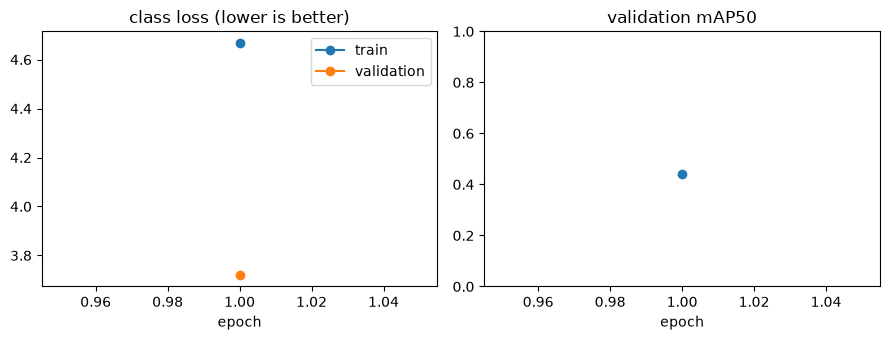

In [6]:
import matplotlib.pyplot as plt

run_dir = ROOT / PROJECT / RUN_NAME
hist = pd.read_csv(run_dir / "results.csv"); hist.columns = [c.strip() for c in hist.columns]
display(hist[["epoch", "train/cls_loss", "val/cls_loss", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].round(3))

fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
axs[0].plot(hist["epoch"], hist["train/cls_loss"], "o-", label="train"); axs[0].plot(hist["epoch"], hist["val/cls_loss"], "o-", label="validation")
axs[0].set_title("class loss (lower is better)"); axs[0].set_xlabel("epoch"); axs[0].legend()
axs[1].plot(hist["epoch"], hist["metrics/mAP50(B)"], "o-"); axs[1].set_title("validation mAP50"); axs[1].set_xlabel("epoch"); axs[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

## 6. Why `freeze=10`? The overfitting picture
Below are the full 80-epoch runs we trained earlier (kept in `runs/detect/`). *Train* loss falls the same way in both, but with all layers trainable
the *validation* loss turns upwards: the model memorises the training images. With `freeze=10` the gap is much smaller.
(This cell needs the local `runs/detect/` folders; it skips politely if they are missing.)

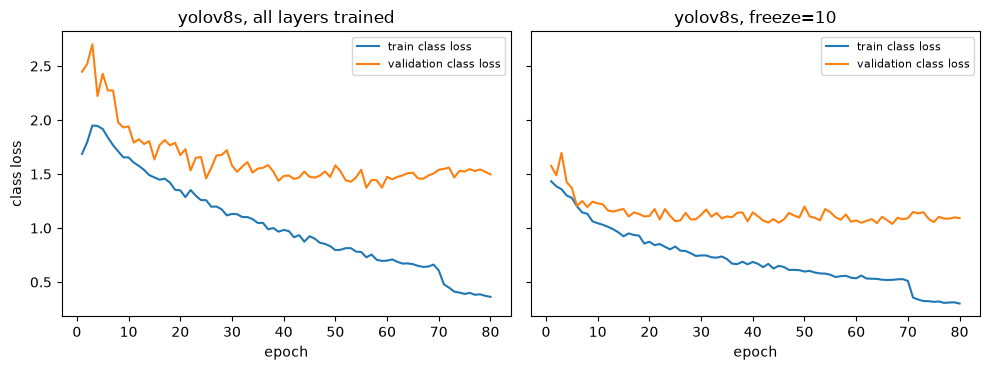

In [7]:
plain, frozen = ROOT / "runs/detect/yolov8s_80ep/results.csv", ROOT / "runs/detect/yolov8s_80ep_freeze10/results.csv"
if plain.exists() and frozen.exists():
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
    for ax, path, title in [(axs[0], plain, "yolov8s, all layers trained"), (axs[1], frozen, "yolov8s, freeze=10")]:
        d = pd.read_csv(path); d.columns = [c.strip() for c in d.columns]
        ax.plot(d["epoch"], d["train/cls_loss"], label="train class loss"); ax.plot(d["epoch"], d["val/cls_loss"], label="validation class loss")
        ax.set_title(title); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
    axs[0].set_ylabel("class loss"); plt.tight_layout(); plt.show()
else:
    print("runs/detect/... not found on this machine; see results/figures/loss_curves.png")

## 7. Keep the weights
`best.pt` is the epoch with the best validation mAP50. A **full run** copies it to `results/weights/<RUN_NAME>.pt`.
It never overwrites `results/weights/best.pt` (the model the website uses); promote a new model by hand only after comparing it on the
validation split.

In [8]:
best = run_dir / "weights/best.pt"
print("best weights of this run:", best, "| exists:", best.exists())
if FULL_RUN and best.exists():
    dst = ROOT / "results/weights" / f"{RUN_NAME}.pt"
    dst.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(best, dst)
    print("copied to", dst)
else:
    print("fast demo run: nothing copied (these weights saw 2% of the data for 1 epoch and are not useful)")

best weights of this run: runs/notebooks/nb_fast/weights/best.pt | exists: True
fast demo run: nothing copied (these weights saw 2% of the data for 1 epoch and are not useful)


## What to take away
- Same recipe + same seed = same result; everything is in the settings cell.
- `freeze=10` is the cheap fix that made fine-tuning work on this small dataset.
- Next: notebook 03 measures the trained model on the test images.